X shape: (990, 10, 1)
y shape: (990,)
Test MSE: 0.00019491642888169736
Test MAE: 0.012145877815783024


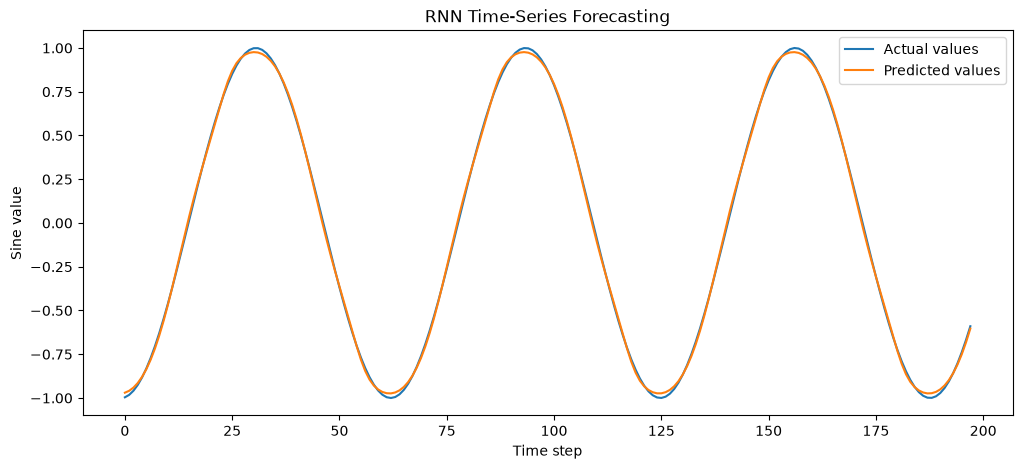

Predicted next value: -0.5158044
Actual next value: -0.5063656411097588


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Step 1: Generate sine-wave data
time = np.arange(0, 100, 0.1)
data = np.sin(time)

# Step 2: Create sliding windows
window_size = 10

X = []
y = []

for i in range(len(data) - window_size):
    X.append(data[i:i + window_size])
    y.append(data[i + window_size])

X = np.array(X)
y = np.array(y)

# Step 3: Reshape for RNN
# (samples, time steps, features)
X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

# Step 4: Split data chronologically
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# Step 5: Build RNN model
model = Sequential([
    SimpleRNN(32, activation="tanh",
              input_shape=(window_size, 1)),
    Dense(1)
])

# Step 6: Compile model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Step 7: Train model
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=0
)

# Step 8: Evaluate model
loss, mae = model.evaluate(X_test, y_test, verbose=0)

print("Test MSE:", loss)
print("Test MAE:", mae)

# Step 9: Predict next values
predictions = model.predict(X_test, verbose=0)

# Step 10: Plot actual vs predicted values
plt.figure(figsize=(12, 5))
plt.plot(y_test[:200], label="Actual values")
plt.plot(predictions[:200], label="Predicted values")
plt.title("RNN Time-Series Forecasting")
plt.xlabel("Time step")
plt.ylabel("Sine value")
plt.legend()
plt.show()

# Step 11: Predict the next value from latest 10 points
latest_10 = data[-window_size:].reshape(1, window_size, 1)
next_value = model.predict(latest_10, verbose=0)

print("Predicted next value:", next_value[0][0])
print("Actual next value:", np.sin(time[-1] + 0.1))